# 04 - Which Posts Are Unusual? (Anomaly Detection)
**Isolation Forest** finds posts that are very different from the rest.
Each post is compared **only with posts of the same content type** (a reel is compared with reels).

In [1]:
import sys, pandas as pd, matplotlib.pyplot as plt
sys.path.append("..")          # so that engine.py can be imported
import engine as E
posts = pd.read_csv("../data/posts.csv")
comments = pd.read_csv("../data/comments.csv")
posts = E.add_metrics(posts)   # adds the engagement_rate column

In [2]:
an = E.find_anomalies(posts)
print('Anomalous posts:', an.anomaly.sum(), 'out of', len(an))
an[an.anomaly].sort_values('anomaly_score', ascending=False)[['post_id','platform','campaign','content_type','views','likes','comments_count','engagement_rate']].head(10)

Anomalous posts: 80 out of 2000


,post_id,platform,campaign,content_type,views,likes,comments_count,engagement_rate
1725,P1726,TikTok,12.12 Sale,Reel,33066,10668,2508,40.325410
386,P0387,Facebook,11.11 Sale,Influencer Post,14868,4612,876,37.220877
1518,P1519,Facebook,12.12 Sale,Sale Announcement,40833,7496,1914,23.429579
810,P0811,Facebook,12.12 Sale,Product Photo,57205,8764,1614,18.351543
304,P0305,Facebook,Eid Collection,Sale Announcement,12076,2060,444,21.149387
248,P0249,Facebook,12.12 Sale,Product Photo,69996,461,2652,4.854563
1296,P1297,Instagram,11.11 Sale,Styling Video,28603,5768,894,23.602419
1059,P1060,Instagram,11.11 Sale,Reel,67143,599,4188,7.594239
641,P0642,Facebook,Eid Collection,Product Photo,6574,45,240,4.745969
1475,P1476,Facebook,11.11 Sale,Styling Video,32766,177,1554,5.734603


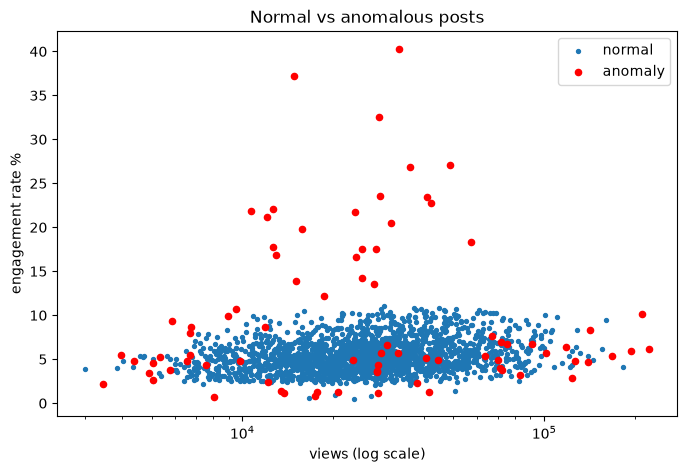

In [3]:
plt.figure(figsize=(8,5))
plt.scatter(an[~an.anomaly].views, an[~an.anomaly].engagement_rate, s=8, label='normal')
plt.scatter(an[an.anomaly].views, an[an.anomaly].engagement_rate, s=20, color='red', label='anomaly')
plt.xscale('log'); plt.xlabel('views (log scale)'); plt.ylabel('engagement rate %'); plt.legend(); plt.title('Normal vs anomalous posts')
plt.show()

## Sensitivity: how does the `contamination` setting change the result?

In [4]:
for c in [0.02, 0.04, 0.08]:
    print(c, '->', E.find_anomalies(posts, contamination=c).anomaly.sum(), 'posts')

0.02 -> 40 posts
0.04 -> 80 posts
0.08 -> 160 posts


## My observations
- Two posts have extremely high engagement: a TikTok Reel (about 40%) and a Facebook Influencer Post (about 37%), while normal posts stay below 10%.
- Some posts have an unusual pattern: very many comments but very few likes (for example a Product Photo with about 70,000 views, only 461 likes and 2,652 comments). This could signal a problem or controversy and should be checked manually.
- The number of anomalies depends on the contamination setting (40, 80 or 160 posts at 2%, 4% and 8%), so the team should choose it based on how many posts they can review.


- ...